[Data Cleaning](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_cleaning.html) fixed what was wrong with the data: gaps, repeats,
and values that could not be true. Clean data is not always in the form an analysis
needs, though. A comparison may be clearer between a few groups than across hundreds of
distinct values. A method may need numbers where the data has categories. Two columns may
need to be put on a common scale before they can be combined fairly.

This chapter is about reshaping clean data for the question you want to ask, without
changing what it says. Each preparation step is a choice — how many groups and where
their edges fall, how to turn a category into numbers, which columns to rescale — and
each choice changes what the next step can see. The habit to build is checking the
result of every choice before you trust it.

By the end of this chapter you should be able to:

- Bin a numeric column with `pd.cut()` (equal widths, or edges you choose) and `pd.qcut()` (equal counts), and check the bin counts before comparing groups.
- Compare an outcome across bins with `groupby()` and `mean()`, and describe the pattern as an association, naming what else could explain it.
- Encode categories as numbers: a code with `map()` when the categories have a meaningful order, and one indicator column per category with `pd.get_dummies()` when they do not.
- Rescale numeric columns with min–max scaling and standardization, and say which columns must not be rescaled.

Complete the [practice activity](#practice-activity-bin-encode-and-rescale)
after the worked examples.

## Set Up Your Chapter Files {#set-up-your-chapter-files}

Download the [Data Preparation practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/data-preparation-practice.zip).
Extract `stat303-data-preparation` inside the `chapters` folder of your `stat303-1`
course folder, open `stat303-1` in VS Code, and select the course environment. The
terminal opens in `stat303-1`, so move it into the kit with `cd chapters` and then
`cd stat303-data-preparation` before you render the activity.

```text
stat303-1/
├── .venv/
├── assignments/
└── chapters/
    └── stat303-data-preparation/
        ├── data_preparation_examples.ipynb
        ├── activity11.ipynb
        ├── README.md
        └── data/
            └── College.csv
```

Run `data_preparation_examples.ipynb` for the lesson and complete `activity11.ipynb` for
your own activity report, with `stat303-data-preparation` as the notebook working folder.
The data is read with the relative path `"data/College.csv"`, so the notebooks find it
only when that folder is the working folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Environment check:** This chapter uses NumPy, pandas, matplotlib, and seaborn, all of
which are already in the course environment. If an import fails, check the selected
notebook kernel first: it must be the course environment, `stat303-1/.venv`, as in
[Project Environments, Packages, and File Paths](https://lizhen0909.github.io/stat303-1-sec20-coursebook/python_venv.html#install-packages-in-the-intended-environment).

## The data

This chapter uses the college data from the outlier section of
[Data Cleaning](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_cleaning.html): 777 US colleges, with the college names as row
labels. That chapter found one impossible value, a graduation rate of 118%, and decided
to mark it as missing. The same decision is applied here, before anything else:

In [2]:
college = pd.read_csv("data/College.csv", index_col=0)
college.loc[college["Grad.Rate"] > 100, "Grad.Rate"] = np.nan

print(college.shape)
college[["Private", "Apps", "Top10perc", "Outstate", "Expend", "Grad.Rate"]].head()

(777, 18)


,Private,Apps,Top10perc,Outstate,Expend,Grad.Rate
Abilene Christian University,Yes,1660,23,7440,7041,60.0
Adelphi University,Yes,2186,16,12280,10527,56.0
Adrian College,Yes,1428,22,11250,8735,54.0
Agnes Scott College,Yes,417,60,12960,19016,59.0
Alaska Pacific University,Yes,193,16,7560,10922,15.0


The columns used most below are `Expend` (instructional expenditure per student, in
dollars), `Grad.Rate` (graduation rate, as a percentage), `Outstate` (out-of-state
tuition), `Top10perc` (the percentage of new students from the top 10% of their
high-school class), and `Private` (`"Yes"` or `"No"`).

The question running through the first section is a simple one: **do colleges that spend
more per student graduate more of their students?**

## Bin a numeric column

A scatter plot answers the spending question for every college at once, and with 777
noisy points the answer is hard to read:

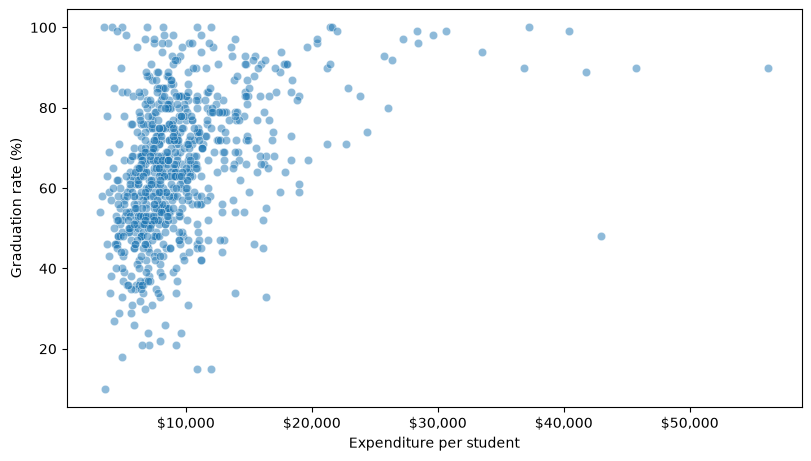

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
sns.scatterplot(data=college, x="Expend", y="Grad.Rate", alpha=0.5, ax=ax)
ax.xaxis.set_major_formatter("${x:,.0f}")
ax.set(xlabel="Expenditure per student", ylabel="Graduation rate (%)")
plt.show()

Each college is one point, and `Expend` alone has hundreds of distinct values. The
standard way to make a comparison like this readable is to bin the column.

### What binning is, and why it helps

**Data binning** groups the values of a numeric column into a few intervals, called
**bins**, and records which bin each value falls into instead of the value itself. Think
of it as sorting a long list of numbers into a few labelled jars. Binning simplifies a
column so that patterns become visible and comparisons become easy to state.

**Why bin?**

- **Easier interpretation.** Instead of hundreds of distinct values, you summarize a
  handful of groups. Rather than every possible age, a report might use the age groups
  "under 20", "20 to 30", "30 to 40", and "40 and over".
- **Targeted decisions.** Groups support decisions made group by group. A doctor may
  recommend different treatments for children, adults, and older adults, each defined by
  an age bin.
- **Less noise.** Grouping smooths random fluctuation. Daily sales may jump around, while
  weekly or monthly totals show the trend.

**Binning in the real world.**

- **Tax brackets.** Income is binned into ranges that are taxed at different rates. For
  a single filer in 2024, the first $11,600 of taxable income is taxed at 10%, the part
  from $11,601 to $47,150 at 12%, and the part above that at 22% or more.
- **Customer segments.** A credit card company may bin customers into high, medium, and
  low spenders and market to each group differently.
- **Medical guidelines.** Vaccine recommendations often depend on age bins, such as under
  12, 12 to 18, 18 to 65, and over 65.

::: {layout-ncol=2}
![Tax brackets bin a taxable income of $50,000 into three ranges, each taxed at its own rate.](https://lizhen0909.github.io/stat303-1-sec20-coursebook/images/binning-tax-brackets.png){width=300}

![A bar chart of counts by binned age: four age groups replace every distinct age.](https://lizhen0909.github.io/stat303-1-sec20-coursebook/images/binning-age-groups.png){width=300}
:::

Here, binning `Expend` into low, medium, and high spending lets you compare one summary
per group instead of reading a cloud of points. The price is detail: once a college is
"medium", the exact dollar figure is gone. That makes the choice of bins, how many and
where their edges fall, the important decision. There are three common ways to make it,
and the rest of this section works through each:

| Method | pandas | Bins have | Suits |
|---|---|---|---|
| Equal-width | `pd.cut(s, k)` | The same width, any count | Values spread fairly evenly |
| Equal-count (quantile) | `pd.qcut(s, k)` | The same count, any width | Skewed columns; groups you want to compare |
| Custom | `pd.cut(s, bins=[...])` | Edges you choose | Thresholds that mean something |

### Equal-width bins with `cut()`

[`pd.cut(column, 3)`](https://pandas.pydata.org/docs/reference/api/pandas.cut.html)
divides the range of a column, from its minimum to its maximum, into 3 intervals of
equal width, and returns which interval each value falls into. `value_counts(sort=False)`
lists the intervals in order with their counts:

In [4]:
pd.cut(college["Expend"], 3).value_counts(sort=False)

Expend
(3132.953, 20868.333]     751
(20868.333, 38550.667]     21
(38550.667, 56233.0]        5
Name: count, dtype: int64

Each interval is written `(left, right]`: the round bracket means the left edge is
excluded and the square bracket means the right edge is included, so every value belongs
to exactly one bin. (The lowest edge sits slightly below the minimum so that the
minimum is included.)

The widths are equal, about $17,700 each, but the counts are not: 751 colleges in the
first bin, 21 in the second, and 5 in the third. `Expend` is strongly right-skewed, as
Data Cleaning showed, so a few very high spenders stretch the range and the top two bins
cover almost no one. Comparing group means anyway gives a misleading answer:

In [5]:
width_level = pd.cut(college["Expend"], 3, labels=["Low", "Medium", "High"])
college.groupby(width_level)["Grad.Rate"].mean().round(1)

Expend
Low       64.6
Medium    90.6
High      83.2
Name: Grad.Rate, dtype: float64

`labels=` names the bins in order, from lowest to highest. The `groupby(...).mean()`
pattern is the one introduced in Data Cleaning, here grouping by the bin each college
falls into.

Read naively, the table says medium spenders graduate the most students. But "medium"
and "high" are 21 and 5 colleges; a single unusual school moves either mean by several
points. **Always check the counts before comparing bins.** Equal-width bins suit columns
whose values are spread fairly evenly. For a skewed column they put nearly everything in
one bin.

### Equal-count bins with `qcut()`

[`pd.qcut(column, 3)`](https://pandas.pydata.org/docs/reference/api/pandas.qcut.html)
does the opposite: it places the edges at the column's quantiles, so each bin holds
roughly the same number of rows. Three equal-count bins are called **tertiles**:

In [6]:
college["expend_level"] = pd.qcut(college["Expend"], 3, labels=["Low", "Medium", "High"])
college["expend_level"].value_counts(sort=False)

expend_level
Low       259
Medium    259
High      259
Name: count, dtype: int64

Each bin now holds 259 colleges. The edges fall at about $7,334 and $9,682, the 33rd and
67th percentiles. Drawing both sets of edges on the distribution shows the difference
between the two methods:

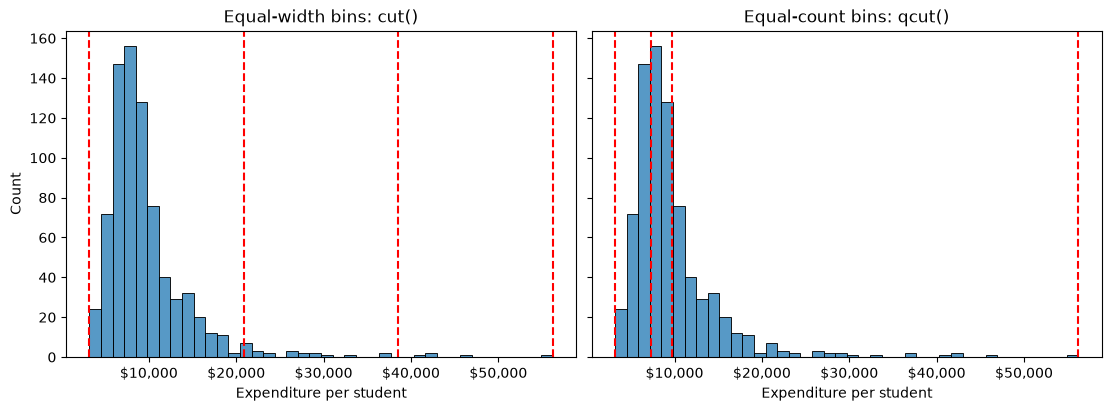

In [7]:
width_edges = np.linspace(college["Expend"].min(), college["Expend"].max(), 4)
count_edges = college["Expend"].quantile([0, 1/3, 2/3, 1])

fig, (ax_width, ax_count) = plt.subplots(1, 2, figsize=(11, 4), sharey=True,
                                         layout="constrained")
for ax, edges, title in [(ax_width, width_edges, "Equal-width bins: cut()"),
                         (ax_count, count_edges, "Equal-count bins: qcut()")]:
    sns.histplot(data=college, x="Expend", bins=40, ax=ax)
    for edge in edges:
        ax.axvline(edge, color="red", linestyle="--")
    ax.xaxis.set_major_formatter("${x:,.0f}")
    ax.set(xlabel="Expenditure per student", title=title)

plt.show()

The red lines are the bin edges. `np.linspace(low, high, 4)` gives four equally spaced
numbers, which are the edges `cut()` used, and `quantile([0, 1/3, 2/3, 1])` gives the
edges `qcut()` used. `ax.axvline(x)` draws a vertical line at `x` across the panel.

On the left, the equal-width edges are evenly spaced, so almost every college lands left
of the first interior line. On the right, the equal-count edges crowd into the dense part
of the distribution, so the bins are narrow where colleges are crowded and wide where they
are sparse. The 5 highest spenders no longer get a bin of their own; they are simply part
of "High". That is a third way of handling extreme values, alongside the removing and
capping in Data Cleaning: an extreme value can only move its bin's mean, not create an
empty bin.

Comparing graduation rates across the tertiles, with the mean for each bar:

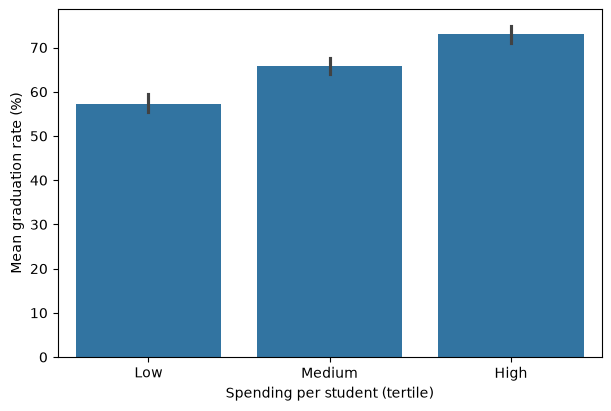

In [8]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
sns.barplot(data=college, x="expend_level", y="Grad.Rate", ax=ax)
ax.set(xlabel="Spending per student (tertile)", ylabel="Mean graduation rate (%)")
plt.show()

Graduation rates rise steadily, from 57.3% to 65.9% to 73.0%. As in
[Data Visualization I](https://lizhen0909.github.io/stat303-1-sec20-coursebook/data_viz_1.html), `barplot` computes the mean of each group for
you, the same `groupby(...).mean()` as above, and the
line on each bar is a 95% confidence interval: none of the three intervals overlap.
The pattern the scatter plot hinted at is now easy to read, and each bar is backed by
259 colleges.

### Bins you choose

Sometimes the edges should come from the question rather than from the data: a budget
category, a policy threshold, a grading cutoff. Pass `cut()` a list of edges instead of
a number of bins:

In [9]:
edges = [0, 10_000, 20_000, np.inf]
labels = ["Under $10K", "$10K to $20K", "$20K and over"]

budget_level = pd.cut(college["Expend"], bins=edges, labels=labels, right=False)
budget_level.value_counts(sort=False)

Expend
Under $10K       535
$10K to $20K     214
$20K and over     28
Name: count, dtype: int64

Three details make custom bins behave:

- **`np.inf`** is infinity, so the last bin has no upper limit and no college can fall
  outside it. Any value outside the edges you give would become `NaN`.
- **`right=False`** closes each interval on the left instead, `[left, right)`, so a
  college spending exactly $10,000 lands in "$10K to $20K", which matches how the labels
  read. Writing `10_000` with an underscore is the same number as `10000`, just easier to
  read.
- **`labels=`** needs one name per bin: three bins from four edges.

These bins answer a budgeting question — how many colleges spend over $20,000 per
student? 28 — at the cost of uneven group sizes, the same trade-off as equal-width bins.

`qcut()` accepts a list too, but its list holds **quantiles** rather than values. This
splits colleges at the median and the 90th percentile, to set the top 10% of spenders
apart:

In [10]:
spending_group = pd.qcut(college["Expend"], [0, 0.5, 0.9, 1],
                         labels=["Bottom half", "50th to 90th percentile", "Top 10%"])
spending_group.value_counts(sort=False)

Expend
Bottom half                389
50th to 90th percentile    310
Top 10%                     78
Name: count, dtype: int64

The list runs from 0 to 1 and the bins hold 50%, 40%, and 10% of the colleges: 389,
310, and 78. Use `cut()` with a list when the edges are values that mean something,
and `qcut()` with a list when they are shares of the data.

### An association, not a recipe

The tertile table invites a recommendation: a college in the low tertile that moved into
the high one could expect its graduation rate to rise by about 16 points. The data cannot
support that. It shows that colleges which spend more *also* graduate more students, not
that spending more *causes* higher graduation. High-spending colleges differ in other
ways too, and one of them is easy to check:

In [11]:
college.groupby("expend_level")[["Grad.Rate", "Top10perc"]].mean().round(1)

,Grad.Rate,Top10perc
expend_level,,
Low,57.3,17.6
Medium,65.9,24.9
High,73.0,40.1


High-spending colleges admit far more students from the top 10% of their high-school
class: 40% against 18%. Students who arrive better prepared are more likely to graduate
wherever they enrol, so selectivity alone could produce much of the pattern. Binning makes
a pattern easier to see; it does not make it a cause. Describe what you find as an
association — "colleges in the highest spending tertile had a mean graduation rate 16
points higher than those in the lowest" — and name what else could explain it.

## Encode categories as numbers

The binned spending levels you just made are categories, and so is `Private`. Working
with them in most analyses requires one more step: turning the categories into numbers.

**Why encode categorical variables?**

- Most statistical and machine-learning methods — correlation, regression, k-nearest
  neighbors, k-means — do arithmetic on their inputs, so every input must be a number.
- Categorical columns often carry some of the most useful information in a dataset, such
  as whether a college is public or private. Leaving them out because they are text throws
  that information away.
- The way you turn categories into numbers is itself a claim. Codes 0, 1, 2 assert an
  order and equal steps, so a poor encoding can mislead a model even when the code runs
  without errors.

Asking pandas how `Private` relates to graduation rates shows the problem at once:

In [12]:
try:
    college["Private"].corr(college["Grad.Rate"])
except ValueError as error:
    print("ValueError:", error)

ValueError: could not convert string to float: 'Yes'


A correlation is computed from arithmetic on both columns, and `"Yes"` cannot take part
in arithmetic. The `try`/`except` lets the notebook show the error and keep running, as
in [NumPy Fundamentals](https://lizhen0909.github.io/stat303-1-sec20-coursebook/numpy_fundamentals.html). How you turn categories into numbers
depends on whether they have an order.

### Two categories: one 0/1 column

A column with only two values becomes a single column of 0s and 1s. `map()`, from
[Pandas Intermediate](https://lizhen0909.github.io/stat303-1-sec20-coursebook/pandas_intermediate.html), replaces each value using a dictionary:

In [13]:
college["private_code"] = college["Private"].map({"No": 0, "Yes": 1})
college[["Private", "private_code"]].head()

,Private,private_code
Abilene Christian University,Yes,1
Adelphi University,Yes,1
Adrian College,Yes,1
Agnes Scott College,Yes,1
Alaska Pacific University,Yes,1


In [14]:
college["private_code"].value_counts()

private_code
1    565
0    212
Name: count, dtype: int64

The counts match the original column, 565 private colleges and 212 public ones, which is
the check worth making after any encoding: a value missing from the dictionary would have
become `NaN`. A 0/1 column is easy to read: its mean, `college["private_code"].mean()`,
is the proportion of private colleges.

The correlation that failed a moment ago now works:

In [15]:
print(round(college["private_code"].corr(college["Grad.Rate"]), 2))

0.34


A correlation of 0.34 says private colleges tend to have higher graduation rates. With a
0/1 column the comparison is easy to check directly: private colleges average about 69%
and public ones about 56%.

### Ordered categories: a code that keeps the order

The spending tertiles have a natural order, so codes 0, 1, and 2 keep a meaning — higher
code, higher spending:

In [16]:
level_codes = {"Low": 0, "Medium": 1, "High": 2}
college["expend_code"] = college["expend_level"].map(level_codes)
college[["Expend", "expend_level", "expend_code"]].head()

,Expend,expend_level,expend_code
Abilene Christian University,7041,Low,0
Adelphi University,10527,High,2
Adrian College,8735,Medium,1
Agnes Scott College,19016,High,2
Alaska Pacific University,10922,High,2


This is **ordinal encoding**. It is only safe when the order is real. Coding three
majors as Biology = 0, CS = 1, Math = 2 would tell any method that CS sits between the
other two and that Math is "twice" CS, which means nothing. Even for ordered categories,
codes 0, 1, 2 claim the steps are equal: that "Low" to "Medium" is the same distance as
"Medium" to "High". When that is doubtful, use the next encoding instead.

### One indicator column per category

[`pd.get_dummies()`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html)
turns a column with *k* categories into *k* **indicator** (or **dummy**) columns, each 1
where the row belongs to that category and 0 elsewhere. A small list of majors shows the
idea:

In [17]:
majors = pd.Series(["Math", "Biology", "CS", "Math", "CS"], name="major")
pd.get_dummies(majors, dtype=int)

,Biology,CS,Math
0,0,0,1
1,1,0,0
2,0,1,0
3,0,0,1
4,0,1,0


No order is implied: each major gets its own column, and every row has exactly one 1.
`dtype=int` asks for 0s and 1s instead of `True` and `False`. This is called **one-hot
encoding**.

One-hot encoding also suits the spending tertiles, even though they are ordered. Their
steps are far from equal: the edge figure showed "Medium" spanning about $2,300, from
$7,334 to $9,682, while "High" spans more than $46,000. Codes 0, 1, 2 would treat those
two steps as the same size. Indicator columns make no claim about step size at all.

The same function works on a DataFrame column. `prefix=` names the new columns after
their source, and `pd.concat(..., axis=1)`, from
[Pandas Fundamentals](https://lizhen0909.github.io/stat303-1-sec20-coursebook/pandas_fundamentals.html), attaches them beside the original
columns:

In [18]:
expend_dummies = pd.get_dummies(college["expend_level"], prefix="expend", dtype=int)
college_encoded = pd.concat([college, expend_dummies], axis=1)
college_encoded[["expend_level", "expend_Low", "expend_Medium", "expend_High"]].head()

,expend_level,expend_Low,expend_Medium,expend_High
Abilene Christian University,Low,1,0,0
Adelphi University,High,0,0,1
Adrian College,Medium,0,1,0
Agnes Scott College,High,0,0,1
Alaska Pacific University,High,0,0,1


The three indicator columns always add up to 1, so any one of them can be worked out
from the other two: a college with 0 in `expend_Medium` and 0 in `expend_High` must be
"Low". For methods such as linear regression, which you will meet in the next course,
that redundancy causes trouble, and the usual fix is to drop one column with
`drop_first=True`:

In [19]:
pd.get_dummies(college["expend_level"], prefix="expend", dtype=int, drop_first=True).head()

,expend_Medium,expend_High
Abilene Christian University,0,0
Adelphi University,0,1
Adrian College,1,0
Agnes Scott College,0,1
Alaska Pacific University,0,1


The dropped category, "Low" here because it comes first, becomes the **reference
category**: a college with 0 in both remaining columns is in it. No information is lost.

| Categories | Encoding | Code |
|---|---|---|
| Two values | One 0/1 column | `s.map({"No": 0, "Yes": 1})` |
| Ordered, equal steps plausible | Ordinal codes | `s.map({"Low": 0, "Medium": 1, "High": 2})` |
| Unordered, or unequal steps | One indicator column per category | `pd.get_dummies(s, prefix="name", dtype=int)` |
| Same, for regression models | Drop one as the reference | add `drop_first=True` |

Indicator columns multiply quickly: a column with 50 categories becomes 50 columns. For
a category with that many values, consider grouping the rare ones together first.

## Rescale numeric columns

Feature scaling is a crucial step in data preparation, especially for machine learning
algorithms that are sensitive to the scale of input features. Scaling ensures that
numerical features contribute equally to model training and prevents features with
larger ranges from dominating those with smaller ranges.

**Why scale features?**

- Many algorithms (e.g., k-nearest neighbors, k-means, principal component analysis,
  gradient descent-based models) compute distances or rely on feature magnitude.
- Features with larger scales can unduly influence the model if not scaled.

A **feature** is a column a method uses as an input; in this chapter, it is simply a
column. The college columns are measured on very different scales:

In [20]:
scale_cols = ["Apps", "Outstate", "Grad.Rate"]
college[scale_cols].describe().round(1)

,Apps,Outstate,Grad.Rate
count,777.0,777.0,776.0
mean,3001.6,10440.7,65.4
std,3870.2,4023.0,17.1
min,81.0,2340.0,10.0
25%,776.0,7320.0,53.0
50%,1558.0,9990.0,65.0
75%,3624.0,12925.0,78.0
max,48094.0,21700.0,100.0


Applications run from 81 to 48,094, tuition from $2,340 to $21,700, and graduation rates
from 10 to 100. To see what that does to a distance, the kind KNN used in Data Cleaning,
compare two colleges. The distance between them adds up the squared difference in each
column, so the share of the total that each column contributes shows which ones count:

In [21]:
pair = ["Amherst College", "Bowdoin College"]
raw = college[scale_cols]

diff = raw.loc[pair[0]] - raw.loc[pair[1]]
pd.DataFrame({
    pair[0]: raw.loc[pair[0]],
    pair[1]: raw.loc[pair[1]],
    "difference": diff,
    "share of squared distance": (diff**2 / (diff**2).sum()).round(3),
})

,Amherst College,Bowdoin College,difference,share of squared distance
Apps,4302.0,3356.0,946.0,0.627
Outstate,19760.0,19030.0,730.0,0.373
Grad.Rate,100.0,96.0,4.0,0.000


Amherst graduates 100% of its students and Bowdoin 96%, a real difference, yet
graduation rate contributes 0.0% of the distance between them. A 4-point gap is
invisible next to differences of hundreds of applications and dollars. Any method built
on this distance would effectively ignore graduation rates.

**Rescaling** puts the columns on a common scale so that each one counts according to
how unusual its difference is, not how big its units are. It changes the units, never the
order of the values within a column.

### Min–max scaling

Min–max scaling maps each column onto the range 0 to 1:

$$x_{\text{scaled}} = \frac{x - \min(x)}{\max(x) - \min(x)}$$

This is what `MinMaxScaler` did before KNN imputation in Data Cleaning. With pandas it is
one line, applied to all three columns at once:

In [22]:
minmax = (raw - raw.min()) / (raw.max() - raw.min())
minmax.describe().round(2)

,Apps,Outstate,Grad.Rate
count,777.00,777.00,776.00
mean,0.06,0.42,0.62
std,0.08,0.21,0.19
min,0.00,0.00,0.00
25%,0.01,0.26,0.48
50%,0.03,0.40,0.61
75%,0.07,0.55,0.76
max,1.00,1.00,1.00


`raw.min()` is a Series with one minimum per column, so pandas subtracts each column's
own minimum from that column. Every column now runs from exactly 0 to 1. A value of 0.5
means "halfway between this column's smallest and largest value", whatever the column
measured.

### Standardization

Standardization converts each value into a **z-score**, the same measure the outlier
rule in Data Cleaning used: how many standard deviations the value is from its column's
mean.

In [23]:
standardized = (raw - raw.mean()) / raw.std()
standardized.describe().round(2)

,Apps,Outstate,Grad.Rate
count,777.00,777.00,776.00
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-0.75,-2.01,-3.24
25%,-0.58,-0.78,-0.73
50%,-0.37,-0.11,-0.02
75%,0.16,0.62,0.74
max,11.65,2.80,2.03


Every column now has mean 0 and standard deviation 1. Unlike min–max scaling, the result
has no fixed range: the most extreme application count sits 11.65 standard deviations
above the mean. A z-score says how unusual a value is, which is often what a comparison
across columns needs.

Back to Amherst and Bowdoin, measured in standard deviations:

In [24]:
diff_z = standardized.loc[pair[0]] - standardized.loc[pair[1]]
(diff_z**2 / (diff_z**2).sum()).round(3).rename("share of squared distance")

Apps         0.405
Outstate     0.223
Grad.Rate    0.372
Name: share of squared distance, dtype: float64

Graduation rate now contributes 37% of the distance. Measured in standard deviations,
the three differences are about the same size: 946 applications is 0.24 of a standard
deviation of 3,870, the $730 tuition gap is 0.18 of $4,023, and the 4-point gap in
graduation rate is 0.23 of 17.1 points. Each column now counts by how unusual its
difference is, not by how big its units are.

Plotting the columns side by side before and after shows what changed and what did not:

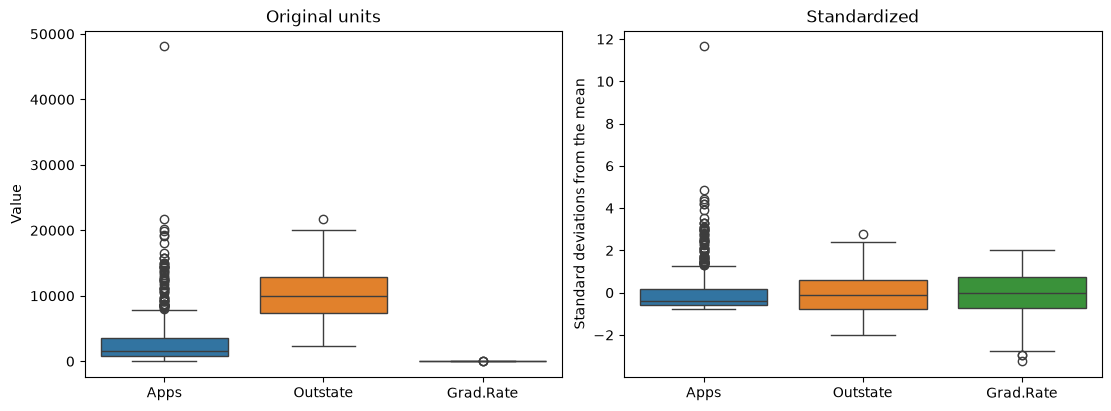

In [25]:
fig, (ax_raw, ax_z) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

sns.boxplot(data=raw, ax=ax_raw)
ax_raw.set(title="Original units", ylabel="Value")

sns.boxplot(data=standardized, ax=ax_z)
ax_z.set(title="Standardized", ylabel="Standard deviations from the mean")

plt.show()

Passing a whole DataFrame as `data=` draws one box per column. On the left, graduation
rate is invisible next to applications; on the right, all three are comparable. The
*shapes* have not changed: applications are just as right-skewed after standardizing as
before. Rescaling is a linear change of units. To reduce skew you need a transformation
such as the log in Data Cleaning.

::: {.callout-note}
## Two standard deviations

`raw.std()` divides by $n - 1$ (pandas' default, `ddof=1`). scikit-learn's
`StandardScaler` divides by $n$ (`ddof=0`), like NumPy, so its z-scores are larger by a
factor of $\sqrt{777/776}$: less than 0.1% for 777 rows. Either is fine as long as you use one
consistently; [NumPy Fundamentals](https://lizhen0909.github.io/stat303-1-sec20-coursebook/numpy_fundamentals.html) covers `ddof`.
:::

### What not to rescale

Rescale only columns that measure a quantity. Leave these alone:

- **Indicator and 0/1 columns** such as `expend_Medium` or `private_code`. A 0/1 column
  already has a clear meaning — in the category or not — and standardizing it would turn
  its values into numbers like −1.6 and 0.6 that mean nothing to a reader.
- **Ordinal codes** such as `expend_code`. The codes are labels for an order, not
  measurements, so their mean and standard deviation are not meaningful.
- **Identifiers** such as an ID number. They are not quantities at all.

| Method | Formula | Result | Use when |
|---|---|---|---|
| Min–max | `(x - x.min()) / (x.max() - x.min())` | Every column from 0 to 1 | You need a fixed range, e.g. before KNN |
| Standardization | `(x - x.mean()) / x.std()` | Mean 0, SD 1 | You want "how unusual" in common units |

Not every method needs rescaling at all. Rescaling matters for methods that combine
columns, through distances as in KNN or through weighted sums. Methods that look at one
column at a time, such as the decision trees you will meet in later courses, which split
the data at a threshold on a single column, give the same result on raw and rescaled
data.

## Summary Cheat Sheet {#summary-cheat-sheet}

**Binning.**

| Goal | Code |
|---|---|
| Equal-width bins | `pd.cut(s, 3, labels=["Low", "Medium", "High"])` |
| Equal-count bins (tertiles) | `pd.qcut(s, 3, labels=[...])` |
| Edges you choose | `pd.cut(s, bins=[0, 10_000, 20_000, np.inf], labels=[...], right=False)` |
| Quantiles you choose | `pd.qcut(s, [0, 0.5, 0.9, 1], labels=[...])` |
| See the edges on the distribution | `ax.axvline(edge)` for each edge, over a histogram |
| Check the counts, in order | `binned.value_counts(sort=False)` |
| Compare an outcome by bin | `df.groupby(binned)["outcome"].mean()` |

**Encoding.**

| Goal | Code |
|---|---|
| Two categories to 0/1 | `s.map({"No": 0, "Yes": 1})` |
| Ordered categories to codes | `s.map({"Low": 0, "Medium": 1, "High": 2})` |
| One indicator column per category | `pd.get_dummies(s, prefix="name", dtype=int)` |
| Drop one as the reference | add `drop_first=True` |
| Attach new columns | `pd.concat([df, dummies], axis=1)` |

**Rescaling.**

| Goal | Code |
|---|---|
| Min–max to [0, 1] | `(df - df.min()) / (df.max() - df.min())` |
| Standardize to z-scores | `(df - df.mean()) / df.std()` |
| Do not rescale | indicator columns, ordinal codes, identifiers |

The rule to remember: **check every preparation step — the bin counts, the encoded
values, the rescaled ranges — before you analyse the result.**

## Practice Activity: Bin, Encode, and Rescale {#practice-activity-bin-encode-and-rescale}

**Goal:** Prepare one column three ways — bin it, encode it, rescale it — and check what each step did.

**File:** `activity11.ipynb` from the [practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/data-preparation-practice.zip).

**Submit:** `activity11.html` through the final upload question in the Data Preparation Canvas quiz.

**This section contains the complete activity instructions.** The starter loads the data and supplies spaces to record your work. Open `activity11.ipynb` from the folder prepared in [Set Up Your Chapter Files](#set-up-your-chapter-files), using the same project environment. The worked examples above are preparation, not additional submission requirements.

The starter loads `college` from the kit's `data/` folder, with the college names as row labels and the impossible graduation rate already set to missing.

### A. Two Ways to Bin Tuition {.unnumbered}

- Replace `Your Name` in the opening Raw cell's `author` field. Run the setup cell; it must report the shape `(777, 18)`.
- Bin `Outstate` into three equal-width bins with `pd.cut()` and into three equal-count bins with `pd.qcut()`, both labelled `"Low"`, `"Medium"`, and `"High"`, and report the counts for each.
- Say which binning you would use to compare groups of colleges, and why.

### B. Describe a Pattern Without Overclaiming {.unnumbered}

- Using your `qcut()` bins, compute the mean `Grad.Rate` for each tuition level and draw a bar plot of it.
- Compute the mean `Top10perc` for the same bins.
- Write two sentences: one describing how graduation rates differ across tuition levels, and one explaining why the `Top10perc` result stops you from concluding that raising tuition raises graduation rates.

### C. Encode Two Columns {.unnumbered}

- Encode `Private` as 0/1 with `map()`, and confirm the counts match the original column.
- Encode your tuition levels as indicator columns with `pd.get_dummies(..., prefix="tuition", dtype=int, drop_first=True)` and attach them to `college` with `pd.concat()`.
- Name the reference category and explain why dropping its column loses no information.

### D. Rescale, and Know What to Leave Alone {.unnumbered}

- Standardize `Apps`, `Outstate`, and `Grad.Rate`, and show that each standardized column has mean 0 and standard deviation 1.
- Apply min–max scaling to the same three columns and show that each runs from 0 to 1.
- Name the columns you created in Part C that must not be rescaled, and say why.

### Render and Submit {.unnumbered}

Restart the kernel, run all cells in order, resolve unexpected errors, and save. Include your outputs and explanations for A–D, and a short Markdown completion note. From `stat303-data-preparation` in the terminal, run:

```text
quarto render activity11.ipynb --to html
```

Follow the [Quarto refresher](https://lizhen0909.github.io/stat303-1-sec20-coursebook/vscode_setup.html#render-and-submit-with-quarto): inspect the HTML and a copy opened outside the project folder, and confirm that every output appears and your name is on the report. Upload only `activity11.html` to the Data Preparation Canvas quiz; keep your notebook locally.

**HTML grading (16 points):** both binnings with their counts and a justified choice (4); mean graduation rate and bar plot, mean `Top10perc`, and the two sentences (4); both encodings with the count check, the reference category, and the explanation (4); both rescalings with their checks and the columns left alone (3); name, readable report, and completion note (1).

## Extended Practice {#extended-practice}

These longer exercises are additional practice, not requirements for the Canvas quiz.
Work in a separate notebook beside your activity and load the data the way the chapter
does. Include your code, outputs, and explanations.

### How Many Bins?

Bin `Expend` into 3, 5, and 10 equal-count bins with `pd.qcut()`, and plot the mean
graduation rate for each binning as a line, one panel per binning, with a shared y-axis.
What does each version show that the others hide? At what point do the bins start to
show noise rather than pattern?

### Grading Bands for Graduation Rates

Create custom bins for `Grad.Rate` with edges at 50, 70, and 85, open-ended at both
ends, and labels that read naturally. Check the counts, including how the one missing
graduation rate is handled, and compare the share of private colleges in each band.

### Does Selectivity Explain It?

Bin `Top10perc` into tertiles. Then, one selectivity tertile at a time, keep only those
colleges with a Boolean filter and compare their mean graduation rates across spending
tertiles with the chapter's `groupby(...).mean()`. Does the spending pattern survive once
selectivity is held roughly fixed? What does that suggest about the chapter's
"association, not a recipe" warning?

### Which College Is Most Unusual?

Standardize all the numeric columns, then compute for each college the square root of
the sum of its squared z-scores — its distance from the "average college". List the five
most unusual colleges and, for each, the column that contributes most. Repeat with
min–max scaling. Do the two methods agree?

## Before You Move On {#before-you-move-on}

The habit to carry forward is checking each preparation step before you trust it.
Binning hides detail and can hide a problem with it, which is why the counts come first.
Encoding replaces words with numbers that carry claims about order and distance. Rescaling
changes units and, if applied to the wrong columns, meaning. Each check is one line, and
each catches a mistake that would otherwise travel silently into every result that
follows.

The other habit is saying what a prepared comparison does and does not show. A cleaner
picture of a pattern is still a picture of an association.

For any dataset you prepare, you should be able to answer five questions:

1. Why did you bin this column, and why these edges?
2. How many rows fell into each bin?
3. Does the pattern across bins have another explanation you can check?
4. Which encoding did each categorical column get, and does it imply an order that is not there?
5. Which columns did you rescale, and which did you deliberately leave alone?

Continue to [Data Grouping and Aggregation](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data%20aggregation.html), where the
`groupby()` you have been using for one mean at a time becomes a full tool for
summarizing data by group.

References: [`pd.cut`](https://pandas.pydata.org/docs/reference/api/pandas.cut.html),
[`pd.qcut`](https://pandas.pydata.org/docs/reference/api/pandas.qcut.html),
[`Series.map`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html),
[`pd.get_dummies`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html),
[`pd.concat`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html),
[`DataFrame.groupby`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html),
and [scikit-learn `StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).